<a href="https://colab.research.google.com/github/taniatygq2-prog/Proyecto-Fundamentos-/blob/main/Parte3_Proyecto.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [30]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

np.random.seed(42) #Sirve para que los resultados se puedan repetir
print("Librerias listas")

Librerias listas


In [31]:
fs = 48_000 #Frecuencia de muestreo (Hz)
fc = 6_000 #Frecuencia de portadora (Hz)
Rs = 800 #tasa de símbolos (simbolos/s)

sps = fs // Rs #Muestra de simbolos
N_SIMBOLOS = 16 #Simbolos por señal
N = sps * N_SIMBOLOS #Muestras por señal
t = np.arange(N) / fs #Vector de tiempo

print(f"Muestras por símbolo: {sps} | Muestras por señal: {N}")
assert fs >= 2 * (fc + 2*Rs), "Nyquist no se cumple"

Muestras por símbolo: 60 | Muestras por señal: 960


In [32]:
def normalizar(s):
    return s / np.sqrt(np.mean(s**2))   # potencia = 1

def repetir(simbolos):
    return np.repeat(simbolos, sps)     # cada símbolo dura sps muestras

def gen_ask(rng):
    bits = rng.integers(0, 2, N_SIMBOLOS)
    amp = np.where(bits == 1, 1.0, 0.3)          # 1 = amplitud 1.0, 0 = amplitud 0.3
    return normalizar(repetir(amp) * np.cos(2*np.pi*fc*t))

def gen_fsk(rng, delta=1_200):
    bits = rng.integers(0, 2, N_SIMBOLOS)
    f_inst = fc + (2*repetir(bits) - 1) * delta  # 1 = 7,200 Hz, 0 = 4,800 Hz
    fase = 2*np.pi*np.cumsum(f_inst) / fs
    return normalizar(np.cos(fase))

def gen_psk(rng):
    fases = np.array([np.pi/4, 3*np.pi/4, 5*np.pi/4, 7*np.pi/4])   # QPSK
    fase = repetir(fases[rng.integers(0, 4, N_SIMBOLOS)])
    return normalizar(np.cos(2*np.pi*fc*t + fase))

def gen_qam16(rng):
    niveles = np.array([-3, -1, 1, 3])
    I = niveles[rng.integers(0, 4, N_SIMBOLOS)]
    Q = niveles[rng.integers(0, 4, N_SIMBOLOS)]
    s = repetir(I)*np.cos(2*np.pi*fc*t) - repetir(Q)*np.sin(2*np.pi*fc*t)
    return normalizar(s)

GENERADORES = {"ASK": gen_ask, "FSK": gen_fsk, "PSK": gen_psk, "16QAM": gen_qam16}
print("Generadores listos:", list(GENERADORES))

Generadores listos: ['ASK', 'FSK', 'PSK', '16QAM']


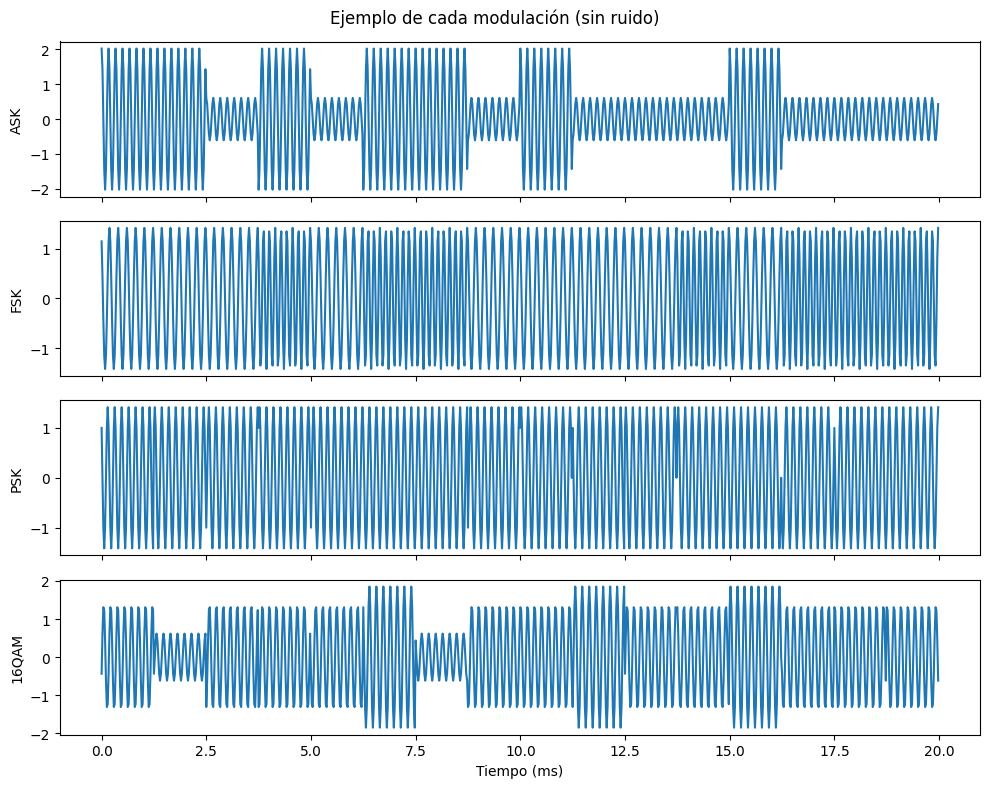

In [33]:
rng = np.random.default_rng(5)
fig, ax = plt.subplots(4, 1, figsize=(10, 8), sharex=True)
for a, (nombre, gen) in zip(ax, GENERADORES.items()):
    a.plot(t*1000, gen(rng))
    a.set_ylabel(nombre)
ax[-1].set_xlabel("Tiempo (ms)")
plt.suptitle("Ejemplo de cada modulación (sin ruido)")
plt.tight_layout()
plt.show()

In [34]:
rng = np.random.default_rng(123)
MUESTRAS_POR_MOD = 1_000

X_limpio = []   # formas de onda
y = []          # etiquetas

for nombre, gen in GENERADORES.items():
    for _ in range(MUESTRAS_POR_MOD):
        X_limpio.append(gen(rng))
        y.append(nombre)

X_limpio = np.array(X_limpio, dtype=np.float32)
y = np.array(y)

print("Forma de X_limpio:", X_limpio.shape)
print("Etiquetas:", np.unique(y, return_counts=True))

Forma de X_limpio: (4000, 960)
Etiquetas: (array(['16QAM', 'ASK', 'FSK', 'PSK'], dtype='<U5'), array([1000, 1000, 1000, 1000]))


In [35]:
def agregar_awgn(senal, snr_db, rng):
    p_senal = np.mean(senal**2)                 # potencia de la señal
    p_ruido = p_senal / (10 ** (snr_db / 10))   # potencia de ruido según el SNR
    ruido = rng.normal(0, np.sqrt(p_ruido), size=senal.shape)
    return (senal + ruido).astype(np.float32)

# Comprobación: el SNR medido debe parecerse al pedido
rng = np.random.default_rng(1)
s = X_limpio[3000]                  # una señal 16-QAM
r = agregar_awgn(s, 10, rng)
snr_medido = 10 * np.log10(np.mean(s**2) / np.mean((r - s)**2))
print(f"SNR pedido: 10 dB | SNR medido: {snr_medido:.2f} dB")

SNR pedido: 10 dB | SNR medido: 10.10 dB


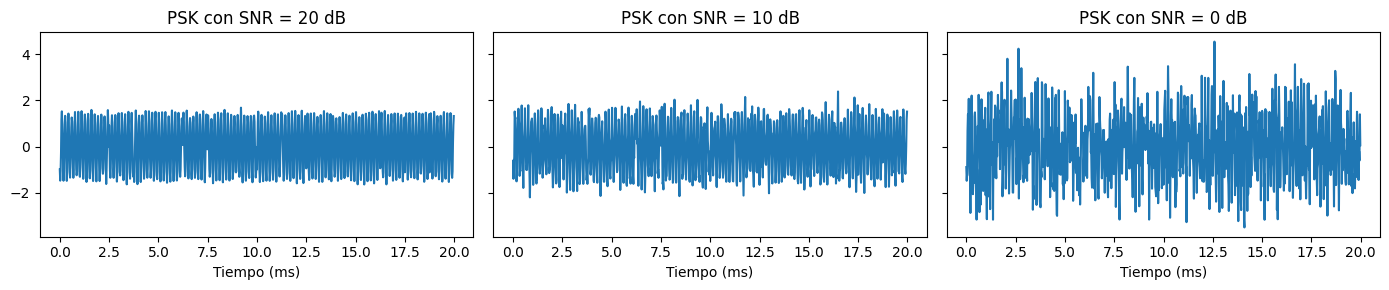

In [36]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3), sharey=True)
rng = np.random.default_rng(2)
base = X_limpio[2000]               # una señal PSK
for a, snr in zip(ax, [20, 10, 0]):
    a.plot(t*1000, agregar_awgn(base, snr, rng))
    a.set_title(f"PSK con SNR = {snr} dB")
    a.set_xlabel("Tiempo (ms)")
plt.tight_layout()
plt.show()

In [37]:
SNRS_DB = [0, 5, 10, 15, 20]
rng = np.random.default_rng(456)

X, etiquetas, snr_lista = [], [], []
for snr in SNRS_DB:
    for i in range(len(X_limpio)):
        X.append(agregar_awgn(X_limpio[i], snr, rng))
        etiquetas.append(y[i])
        snr_lista.append(snr)

X = np.array(X, dtype=np.float32)
etiquetas = np.array(etiquetas)
snr_arr = np.array(snr_lista)

print("Forma de X:", X.shape)
print("Etiquetas:", np.unique(etiquetas, return_counts=True))

Forma de X: (20000, 960)
Etiquetas: (array(['16QAM', 'ASK', 'FSK', 'PSK'], dtype='<U5'), array([5000, 5000, 5000, 5000]))


In [38]:
# Dividimos primero las 4,000 señales ORIGINALES (estratificado por modulación)
ids = np.arange(len(X_limpio))
ids_train, ids_test = train_test_split(
    ids, test_size=0.20, random_state=42, stratify=y
)

# A cada fila de X le corresponde su señal original (se repite por cada SNR)
id_original = np.tile(ids, len(SNRS_DB))

mask_train = np.isin(id_original, ids_train)
mask_test = ~mask_train

X_train, y_train, snr_train = X[mask_train], etiquetas[mask_train], snr_arr[mask_train]
X_test, y_test, snr_test = X[mask_test], etiquetas[mask_test], snr_arr[mask_test]

print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)
print("Entrenamiento por clase:", np.unique(y_train, return_counts=True))
print("Prueba por clase:", np.unique(y_test, return_counts=True))

Entrenamiento: (16000, 960) | Prueba: (4000, 960)
Entrenamiento por clase: (array(['16QAM', 'ASK', 'FSK', 'PSK'], dtype='<U5'), array([4000, 4000, 4000, 4000]))
Prueba por clase: (array(['16QAM', 'ASK', 'FSK', 'PSK'], dtype='<U5'), array([1000, 1000, 1000, 1000]))


SEMANA 2 DISEÑO Y ENTRETENIMIENTO DEL MODELO

In [39]:
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical

le = LabelEncoder()
y_train_int = le.fit_transform(y_train)
y_test_int = le.transform(y_test)

y_train_cat = to_categorical(y_train_int, 4)
y_test_cat = to_categorical(y_test_int, 4)

# La CNN espera (muestras, longitud, canales)
X_train_cnn = X_train[..., np.newaxis]
X_test_cnn = X_test[..., np.newaxis]

print("Clases:", le.classes_)
print("Entrada:", X_train_cnn.shape)

Clases: ['16QAM' 'ASK' 'FSK' 'PSK']
Entrada: (16000, 960, 1)


In [40]:
from tensorflow import keras
from tensorflow.keras import layers

longitud = X_train_cnn.shape[1]   # 960

modelo = keras.Sequential([
    layers.Input(shape=(longitud, 1)),                     # capa de entrada
    layers.Conv1D(32, kernel_size=7, activation="relu"),   # 1.ª Conv1D con ReLU
    layers.Conv1D(64, kernel_size=5, activation="relu"),   # 2.ª Conv1D con ReLU
    layers.Flatten(),                                      # Flatten
    layers.Dense(4, activation="softmax"),                 # salida: 4 neuronas
])

modelo.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_2 (Conv1D)               │ (None, 954, 32)        │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 950, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 60800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │       243,204 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 253,764 (991.27 KB)

 Trainable params: 253,764 (991.27 KB)

 Non-trainable params: 0 (0.00 B)

In [41]:
modelo.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
print("Modelo compilado")

Modelo compilado


In [42]:
# Barajar los datos: están ordenados por nivel de SNR y, sin barajar,
# la validación tomaría solo las señales de 20 dB
idx = np.random.permutation(len(X_train_cnn))
X_train_cnn = X_train_cnn[idx]
y_train_cat = y_train_cat[idx]
snr_train = snr_train[idx]

historial = modelo.fit(
    X_train_cnn, y_train_cat,
    epochs=10,
    batch_size=64,
    validation_split=0.2,
    verbose=1,
)

Epoch 1/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 20s 93ms/step - accuracy: 0.9405 - loss: 0.1279 - val_accuracy: 0.9750 - val_loss: 0.0545
Epoch 2/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 20s 90ms/step - accuracy: 0.9951 - loss: 0.0159 - val_accuracy: 0.9894 - val_loss: 0.0269
Epoch 3/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 20s 87ms/step - accuracy: 0.9988 - loss: 0.0051 - val_accuracy: 0.9950 - val_loss: 0.0182
Epoch 4/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 21s 90ms/step - accuracy: 1.0000 - loss: 0.0015 - val_accuracy: 0.9950 - val_loss: 0.0168
Epoch 5/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 21s 90ms/step - accuracy: 1.0000 - loss: 4.5101e-04 - val_accuracy: 0.9937 - val_loss: 0.0181
Epoch 6/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 21s 91ms/step - accuracy: 1.0000 - loss: 2.1694e-04 - val_accuracy: 0.9950 - val_loss: 0.0177
Epoch 7/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 17s 87ms/step - accuracy: 1.0000 - loss: 1.5802e-04 - val_accuracy: 0.9934 - val_loss: 0.0187
Epoch 8/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 18s 89ms/step - accuracy: 1.0000 - los

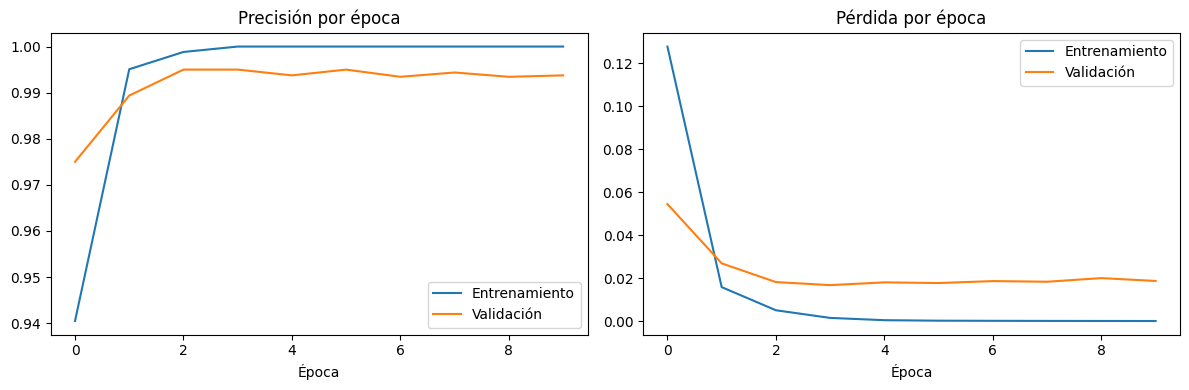

In [43]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(historial.history["accuracy"], label="Entrenamiento")
ax[0].plot(historial.history["val_accuracy"], label="Validación")
ax[0].set_title("Precisión por época")
ax[0].set_xlabel("Época")
ax[0].legend()

ax[1].plot(historial.history["loss"], label="Entrenamiento")
ax[1].plot(historial.history["val_loss"], label="Validación")
ax[1].set_title("Pérdida por época")
ax[1].set_xlabel("Época")
ax[1].legend()

plt.tight_layout()
plt.show()

In [44]:
modelo.save("modelo_detective.keras")
print("Modelo guardado")

from google.colab import files
files.download("modelo_detective.keras")

Modelo guardado


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

TERCERA PARTE


Precisión global en prueba: 0.9940


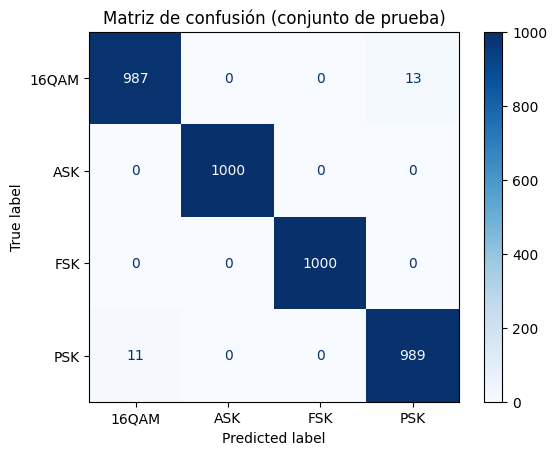

In [45]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_pred = np.argmax(modelo.predict(X_test_cnn, verbose=0), axis=1)
print(f"Precisión global en prueba: {np.mean(y_pred == y_test_int):.4f}")

cm = confusion_matrix(y_test_int, y_pred)
ConfusionMatrixDisplay(cm, display_labels=le.classes_).plot(cmap="Blues")
plt.title("Matriz de confusión (conjunto de prueba)")
plt.show()

SNR  0 dB -> precisión 0.9725 (800 señales)
SNR  5 dB -> precisión 0.9975 (800 señales)
SNR 10 dB -> precisión 1.0000 (800 señales)
SNR 15 dB -> precisión 1.0000 (800 señales)
SNR 20 dB -> precisión 1.0000 (800 señales)


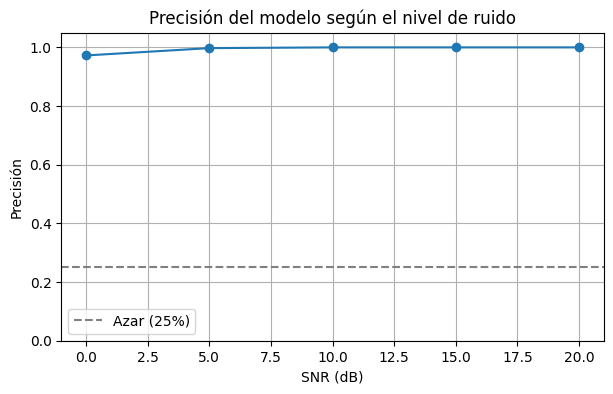

In [46]:
snrs = sorted(np.unique(snr_test))
precisiones = []
for s in snrs:
    m = snr_test == s
    acc = np.mean(y_pred[m] == y_test_int[m])
    precisiones.append(acc)
    print(f"SNR {s:>2} dB -> precisión {acc:.4f} ({m.sum()} señales)")

plt.figure(figsize=(7, 4))
plt.plot(snrs, precisiones, marker="o")
plt.axhline(0.25, color="gray", linestyle="--", label="Azar (25%)")
plt.xlabel("SNR (dB)")
plt.ylabel("Precisión")
plt.title("Precisión del modelo según el nivel de ruido")
plt.ylim(0, 1.05)
plt.grid(True)
plt.legend()
plt.show()

SNR -20 dB -> precisión 0.2500
SNR -15 dB -> precisión 0.2500
SNR -10 dB -> precisión 0.3262
SNR  -5 dB -> precisión 0.8187
SNR   0 dB -> precisión 0.9688
SNR   5 dB -> precisión 0.9962
SNR  10 dB -> precisión 0.9988
SNR  20 dB -> precisión 1.0000


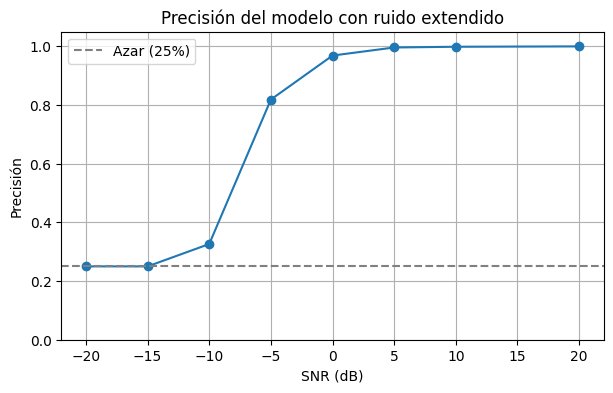

In [47]:
# Prueba extendida: mismas 800 señales originales de prueba, con ruido más fuerte
rng = np.random.default_rng(999)
X_orig_test = X_limpio[ids_test]
y_orig_test = le.transform(y[ids_test])

snrs_ext = [-20, -15, -10, -5, 0, 5, 10, 20]
prec_ext = []
for s in snrs_ext:
    Xn = np.array([agregar_awgn(x, s, rng) for x in X_orig_test])[..., np.newaxis]
    pred = np.argmax(modelo.predict(Xn, verbose=0), axis=1)
    acc = np.mean(pred == y_orig_test)
    prec_ext.append(acc)
    print(f"SNR {s:>3} dB -> precisión {acc:.4f}")

plt.figure(figsize=(7, 4))
plt.plot(snrs_ext, prec_ext, marker="o")
plt.axhline(0.25, color="gray", linestyle="--", label="Azar (25%)")
plt.xlabel("SNR (dB)")
plt.ylabel("Precisión")
plt.title("Precisión del modelo con ruido extendido")
plt.ylim(0, 1.05)
plt.grid(True)
plt.legend()
plt.show()

SNR    16QAM     ASK     FSK     PSK   | predicciones por clase
 -20   0.000   0.000   0.000   1.000   | [  0   0   0 800]
 -10   0.005   0.130   0.160   0.995   | [  2  26  32 740]
  -5   0.350   1.000   1.000   0.915   | [ 87 200 200 313]
   0   0.940   1.000   1.000   0.930   | [202 200 200 198]
   5   0.990   1.000   1.000   1.000   | [198 200 200 202]
  10   0.995   1.000   1.000   1.000   | [199 200 200 201]


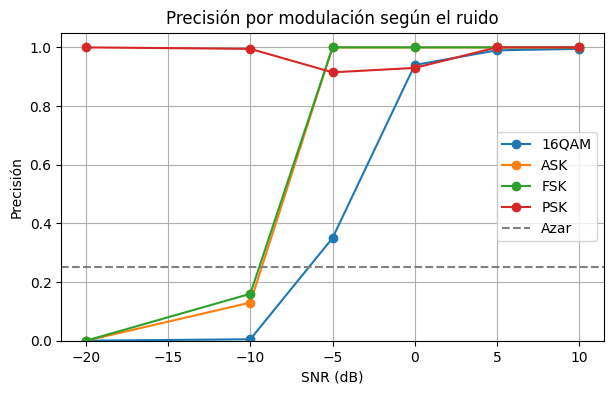

In [48]:
rng = np.random.default_rng(2024)
snrs_ext = [-20, -10, -5, 0, 5, 10]
nombres = list(le.classes_)

print("SNR   " + "  ".join(f"{n:>6}" for n in nombres) + "   | predicciones por clase")
curvas = {n: [] for n in nombres}
for s in snrs_ext:
    Xn = np.array([agregar_awgn(x, s, rng) for x in X_orig_test])[..., np.newaxis]
    pred = np.argmax(modelo.predict(Xn, verbose=0), axis=1)
    fila = []
    for c, n in enumerate(nombres):
        acc = np.mean(pred[y_orig_test == c] == c)
        curvas[n].append(acc)
        fila.append(acc)
    cuentas = np.bincount(pred, minlength=4)
    print(f"{s:>4}  " + "  ".join(f"{v:>6.3f}" for v in fila) + f"   | {cuentas}")

plt.figure(figsize=(7, 4))
for n in nombres:
    plt.plot(snrs_ext, curvas[n], marker="o", label=n)
plt.axhline(0.25, color="gray", linestyle="--", label="Azar")
plt.xlabel("SNR (dB)")
plt.ylabel("Precisión")
plt.title("Precisión por modulación según el ruido")
plt.ylim(0, 1.05)
plt.grid(True)
plt.legend()
plt.show()

FASE 4


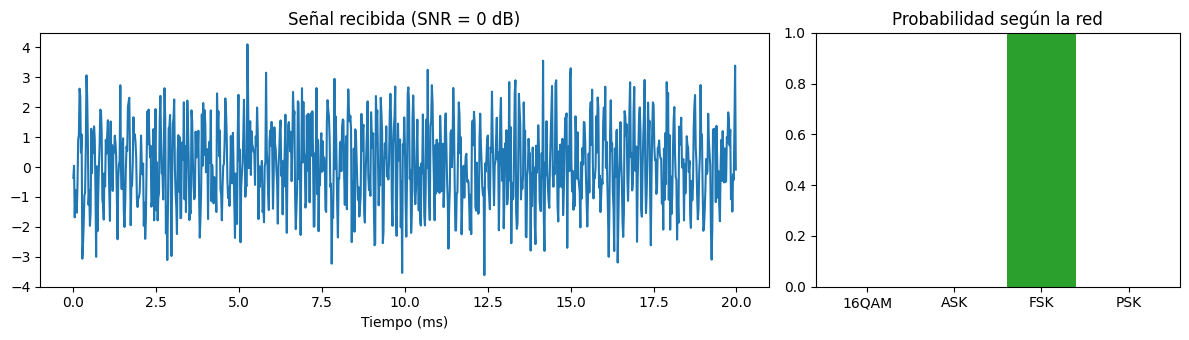

Modulación real: FSK
Predicción de la IA: FSK (100.0% de confianza)
ACIERTO


In [49]:
def demo(modulacion=None, snr_db=None, semilla=None):
    rng = np.random.default_rng(semilla)
    if modulacion is None:
        modulacion = str(rng.choice(list(GENERADORES)))
    if snr_db is None:
        snr_db = int(rng.choice([0, 5, 10, 15, 20]))

    # 1. Se genera una señal NUEVA con ruido
    senal = agregar_awgn(GENERADORES[modulacion](rng), snr_db, rng)

    # 2. La red la clasifica
    probs = modelo.predict(senal[np.newaxis, :, np.newaxis], verbose=0)[0]
    prediccion = str(le.classes_[np.argmax(probs)])

    # 3. Se muestra la señal y lo que "piensa" la red
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.5), gridspec_kw={"width_ratios": [2, 1]})
    ax[0].plot(t*1000, senal)
    ax[0].set_title(f"Señal recibida (SNR = {snr_db} dB)")
    ax[0].set_xlabel("Tiempo (ms)")
    colores = ["tab:green" if c == prediccion else "tab:gray" for c in le.classes_]
    ax[1].bar(le.classes_, probs, color=colores)
    ax[1].set_ylim(0, 1)
    ax[1].set_title("Probabilidad según la red")
    plt.tight_layout()
    plt.show()

    print(f"Modulación real: {modulacion}")
    print(f"Predicción de la IA: {prediccion} ({probs.max()*100:.1f}% de confianza)")
    print("ACIERTO" if prediccion == modulacion else "ERROR")

demo()   # una señal al azar, con modulación y ruido al azar

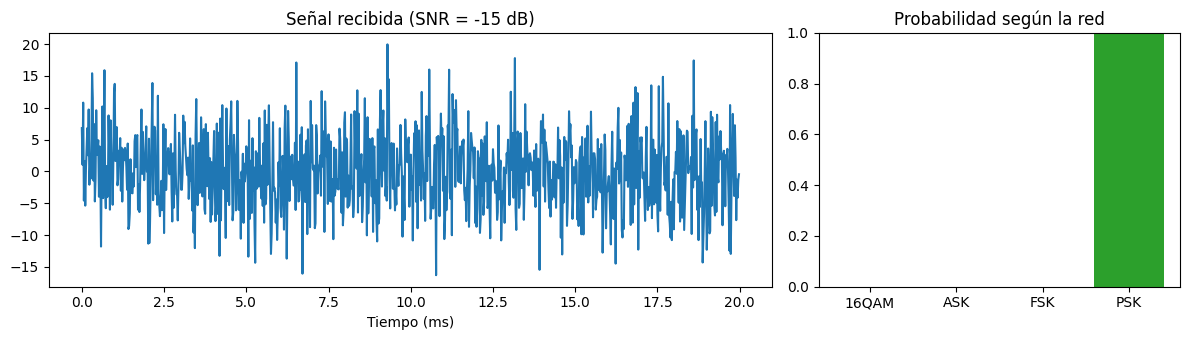

Modulación real: ASK
Predicción de la IA: PSK (100.0% de confianza)
ERROR


In [50]:
demo("ASK", -15)

In [51]:
aciertos = 0
for i in range(50):
    rng = np.random.default_rng(5000 + i)
    mod = str(rng.choice(list(GENERADORES)))
    snr = int(rng.choice([0, 5, 10, 15, 20]))
    s = agregar_awgn(GENERADORES[mod](rng), snr, rng)
    p = modelo.predict(s[np.newaxis, :, np.newaxis], verbose=0)[0]
    aciertos += str(le.classes_[np.argmax(p)]) == mod
print(f"Aciertos: {aciertos} de 50")

Aciertos: 50 de 50
